# Brain Walk · Notebook 4 : décoder

PSY2007D — Laboratoire 1, automne 2026

<table style="width:100%; border-collapse:separate; border-spacing:0; margin:6px 0 10px 0;"><tr><td style="background:#EEF3F9; color:#0B2545; padding:10px 14px; border:3px solid #FFFFFF; border-radius:8px; vertical-align:top; width:25%;"><div style="font-size:0.8em; color:#5B6472;">NOTEBOOK 1</div><div style="font-weight:bold; font-size:1.05em; color:#0B2545;">Prétraitement</div><div style="font-size:0.85em; color:#5B6472;">lire · nettoyer · époques</div></td><td style="background:#EEF3F9; color:#0B2545; padding:10px 14px; border:3px solid #FFFFFF; border-radius:8px; vertical-align:top; width:25%;"><div style="font-size:0.8em; color:#5B6472;">NOTEBOOK 2</div><div style="font-weight:bold; font-size:1.05em; color:#0B2545;">ERP</div><div style="font-size:0.85em; color:#5B6472;">P2 · N400 · LPC · hypothèses H1-H10</div></td><td style="background:#EEF3F9; color:#0B2545; padding:10px 14px; border:3px solid #FFFFFF; border-radius:8px; vertical-align:top; width:25%;"><div style="font-size:0.8em; color:#5B6472;">NOTEBOOK 3</div><div style="font-weight:bold; font-size:1.05em; color:#0B2545;">Rythmes</div><div style="font-size:0.85em; color:#5B6472;">spectres · temps-fréquence</div></td><td style="background:#0B2545; color:#FFFFFF; padding:10px 14px; border:3px solid #FFFFFF; border-radius:8px; vertical-align:top; width:25%;"><div style="font-size:0.8em; color:#C9D6E8;">NOTEBOOK 4</div><div style="font-weight:bold; font-size:1.05em; color:#FFFFFF;">Apprentissage</div><div style="font-size:0.85em; color:#C9D6E8;">décoder · ERP et rythmes</div></td></tr></table>

<div style="border-left:5px solid #5B6472; background:#F3F4F6; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#5B6472;">Ce notebook</b><br>Les notebooks 2 et 3 testent votre hypothèse avec une région et une
fenêtre choisies d'avance. Ici, un modèle cherche lui-même, sur toutes les électrodes et tous les instants : l'EEG permet-il de deviner
la condition, A ou B, de votre hypothèse ? On reprend les stratégies de la séance 5 (notebook 3), sur les données Brain Walk.</div>

**L'unité du notebook : une moyenne par mot.** La fréquence est une propriété des mots : on moyenne, pour chaque mot, les essais de tous les
participants qui l'ont lu (environ 15), puis le modèle apprend sur des mots et il est jugé sur des mots **nouveaux**. Un essai seul est
trop bruité ; une moyenne par personne est très propre, mais il n'y en a que 34. La partie 2.6 compare les trois.

| Partie | Contenu |
|---|---|
| 0 | **Votre hypothèse** ; les données : des essais, puis une moyenne par mot |
| 1 | Le principe : entraîner, tester, comparer au hasard |
| 2 | Votre question : attributs, électrodes, une carte ; **à explorer** : un essai, une moyenne par mot, une moyenne par personne |
| 3 | Trois pièges : le bruit de la marche, le moment de la main, le nombre d'essais |
| 4 | Décoder dans le temps |
| 5 | La posture (H4, H8, H10) et le comportement (H5) |
| 6 | Récapitulatif |
| 7 | **Défis (points bonus)** |

<div style="color:#1F2937; background:#F9FAFB; border:1px solid #E5E7EB; border-radius:6px; padding:8px 14px;"><b>Trois types de blocs</b><div style="margin:3px 0;"><span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> &nbsp;le code est complet : exécutez la cellule et lisez les commentaires.</div><div style="margin:3px 0;"><span style="background:#E8710A; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 2</span> &nbsp;complétez une ou deux lignes marquées <code>&lt;---</code>.</div><div style="margin:3px 0;"><span style="background:#7C3AED; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 3</span> &nbsp;écrivez la cellule vous-même, à partir des indices et des liens vers la documentation.</div><div style="font-size:0.9em; color:#5B6472; margin-top:4px;">Chaque exercice est suivi d'une solution repliée : essayez d'abord.</div></div>

<details><summary>Sur votre ordinateur ou dans Colab ?</summary>

- **Sur votre ordinateur (recommandé)** : les données sont déjà dans `tasks/brainwalk/` si vous avez fait le notebook 1.
- **Colab** : la première cellule installe MNE et télécharge les données (2,2 Go) à **chaque** session. Le notebook prend 3 à 4 minutes.
</details>

In [ ]:
# ---- 0.1 Les paquets (installés s'il en manque), les imports et les données
import importlib.util
import sys
import warnings

DANS_COLAB = "google.colab" in sys.modules
DEPOT = "https://raw.githubusercontent.com/thecocolab/PSY2007D-UdeM/main/"
if DANS_COLAB:                            # Colab n'a pas les fichiers du cours : on les télécharge
    !wget -q -N {DEPOT}requirements.txt {DEPOT}outils_brainwalk.py
PAQUETS = ["mne", "sklearn"]   # les paquets de ce notebook
if any(importlib.util.find_spec(p) is None for p in PAQUETS):   # il en manque : installer ceux du cours (une fois)
    %pip install -q -r requirements.txt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
import sklearn
from scipy import stats
import outils_brainwalk as ob             # fonctions du projet (fichier outils_brainwalk.py, à côté du notebook)

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore", message="Skipping features without any observed values")   # une électrode jamais mesurée
warnings.filterwarnings("ignore", message="Mean of empty slice")          # une moyenne où l'électrode n'est jamais mesurée
warnings.filterwarnings("ignore", message="Degrees of freedom <= 0")      # (idem, pour l'écart-type)
np.seterr(invalid="ignore")
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
DOSSIER = ob.telecharger_donnees()        # déjà là si vous avez fait le notebook 1
print("scikit-learn", sklearn.__version__, "| MNE", mne.__version__)

## 0. Votre hypothèse, et les données

Chaque hypothèse compare deux conditions, **A** et **B** (notebook 2). Le modèle reçoit la moyenne d'un mot et doit deviner : A ou B ?

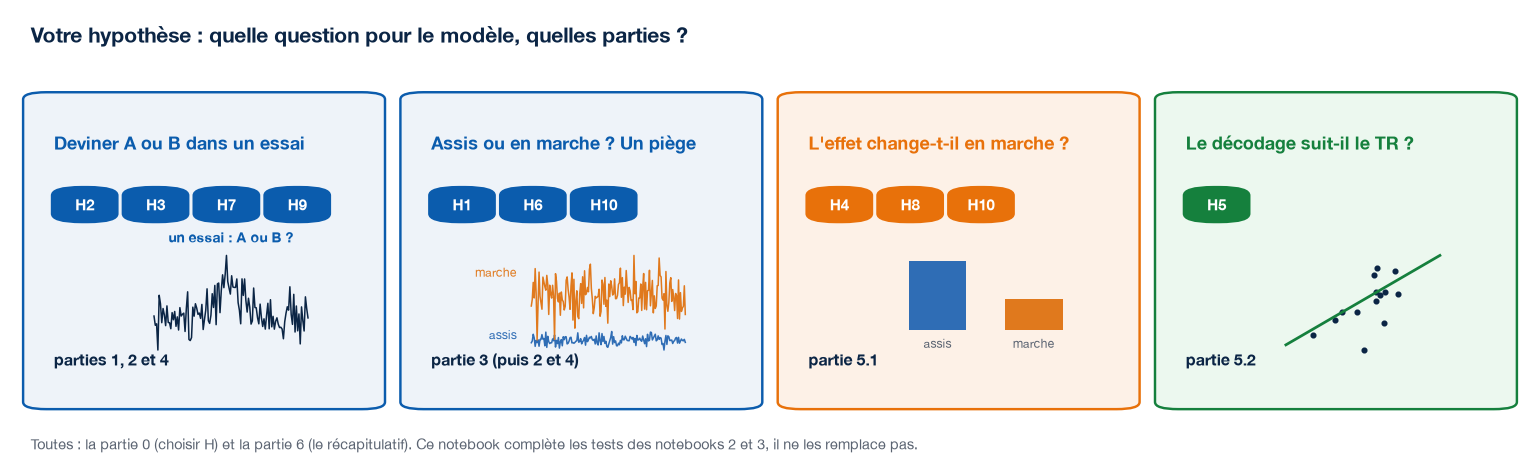

| | Hypothèse (notebook 2) | Le modèle devine | L'attribut ERP (notebook 2) | L'attribut de rythme (notebook 3) | Parties |
|---|---|---|---|---|---|
| H1 | La marche modifie la P200 | assis ou marche | `p200` | `theta_precoce` | **3**, puis 1, 2, 4 |
| H2 | LF diffère de HF dès 180-300 ms | HF ou LF | `p200n250` | `theta_precoce` | 1, 2, 4 |
| H3 | La N400 est plus négative pour LF | HF ou LF | `n400` | `theta` | 1, 2, 4 |
| H4 | L'effet de fréquence sur la N400 change en marche | HF ou LF, assis puis en marche | `n400` | `theta` | 1, 2, 4, puis **5.1** |
| H5 | L'effet N400 suit l'effet sur le comportement | HF ou LF | `n400` | `theta` | 1, 2, 4, puis **5.2** |
| H6 | La marche modifie la P3/LPC | assis ou marche | `p3` | `theta_tardif` | **3**, puis 1, 2, 4 |
| H7 | La P3/LPC diffère entre LF et HF | HF ou LF | `p3` | `theta_tardif` | 1, 2, 4 |
| H8 | L'effet de fréquence sur la P3/LPC change en marche | HF ou LF, assis puis en marche | `p3` | `theta_tardif` | 1, 2, 4, puis **5.1** |
| H9 | Avant une réponse lente, la CPP monte autrement | rapide ou lent | `cpp` (avant la tape) | `beta_tape` (avant la tape) | 1, 2, **3**, 4 |
| H10 | La marche modifie la CPP, et son effet de fréquence | assis ou marche | `cpp` (avant la tape) | `beta_tape` (avant la tape) | **3**, puis 1, 2, 4, **5.1** |

### <span style="background:#E8710A; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 2</span> 0.2 Vos choix

**Une ligne à changer** : `H = 'H3'`, le numéro de votre hypothèse. La cellule en déduit ce que le modèle devine et les deux attributs
de l'hypothèse : sa composante de l'ERP (notebook 2) et sa mesure de rythme (notebook 3), chacune dans sa région. Exécutez ensuite les
cellules dans l'ordre.

In [ ]:
# ---- 0.2 Vos choix
H = "H3"                       # votre hypothèse : "H1" à "H10", la seule ligne à changer

HYPOTHESES = {                 # H : (ce que le modèle devine, l'attribut ERP, l'attribut de rythme) : le tableau du dessus
    "H1": ("posture", "p200", "theta_precoce"),
    "H2": ("frequence", "p200n250", "theta_precoce"),
    "H3": ("frequence", "n400", "theta"),
    "H4": ("frequence", "n400", "theta"),
    "H5": ("frequence", "n400", "theta"),
    "H6": ("posture", "p3", "theta_tardif"),
    "H7": ("frequence", "p3", "theta_tardif"),
    "H8": ("frequence", "p3", "theta_tardif"),
    "H9": ("tr", "cpp", "beta_tape"),
    "H10": ("posture", "cpp", "beta_tape"),
}
QUESTION, ATTRIBUT, RYTHME = HYPOTHESES[H]   # pour explorer : QUESTION = "lexicalite" (mot ou pseudo-mot)
POSTURE = "les deux"           # pour "frequence" et "tr" : les essais "assis", "marche" ou "les deux" (2.6 : ce que cela change)
EGALISER = True                # le même nombre d'essais dans chaque moyenne (0.4 ; partie 3.3 : pourquoi)
REGION = (["C3", "Cz", "C4", "P3", "Pz", "P4"] if ATTRIBUT in ("n400", "p3", "cpp")   # la région de la composante (notebook 2)
          else ["F3", "Fz", "F4", "C3", "Cz", "C4", "P3", "Pz", "P4"])
REGION_RYTHME = {"theta_precoce": ob.REGION_FC, "theta": ob.REGION_CP, "theta_tardif": ob.REGION_CP, "alpha": ob.REGION_PO,
                 "beta_tape": ob.REGION_C}[RYTHME]          # la région de la mesure de rythme (notebook 3)
COLONNE, A, B = ob.QUESTIONS[QUESTION]                     # la colonne du tableau, et les deux conditions
print(f"{H} : {A} (0) ou {B} (1) ? L'attribut ERP : {ATTRIBUT} ({', '.join(REGION)}) ; "
      f"l'attribut de rythme : {RYTHME} ({', '.join(REGION_RYTHME)})")

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> 0.3 Résumer chaque essai par des attributs

Un essai = 19 électrodes × 361 instants. On le résume par des **attributs** (les « caractéristiques » de la séance 5) : un **attribut** =
un nombre qui résume un aspect de l'essai à une électrode, choisi à l'avance ; il devient une colonne du tableau.

| Famille | Attributs | Fenêtre |
|---|---|---|
| ERP (notebook 2) | `p200`, `p200n250`, `n400`, `p3` : l'amplitude moyenne (µV) | 180-250, 180-300, 300-500, 500-800 ms après le mot |
| ERP (notebook 2) | `cpp` : l'amplitude moyenne (µV) | les 500 ms avant la tape |
| Décours | `t100`, `t150`, ..., `t750` : l'amplitude moyenne (µV) de chaque tranche de 50 ms | de 100 à 800 ms après le mot |
| Rythmes (notebook 3) | `theta_precoce`, `theta`, `theta_tardif`, `alpha` : la puissance (dB) | 100-300, 300-500, 500-800, 300-800 ms après le mot |
| Rythmes (notebook 3) | `beta_tape` : la puissance du bêta (dB) | les 500 ms avant la tape |
| Décours des rythmes | `theta0`, ..., `theta700`, puis `alpha...` et `beta...` : la puissance de chaque tranche de 100 ms | de 0 à 800 ms après le mot |

Le **décours** garde la forme de l'onde : 14 tranches de 50 ms au lieu d'une seule fenêtre. Les **rythmes** sont mesurés comme au
notebook 3 : la puissance des ondelettes de Morlet, sur les époques longues, dans chaque essai ; leur décours suit la puissance du thêta
(4-7 Hz), de l'alpha (8-12 Hz) et du bêta (13-30 Hz) toutes les 100 ms. Les colonnes s'appellent `n400_Cz`,
`t300_Pz`... Comme au notebook 2, chaque essai perd sa ligne de base (−0,2 à 0 s avant le mot), aussi autour de la tape. Une électrode
**non mesurée** dans un essai (colonne `mauvaises`) n'a pas de valeur : NaN (« pas un nombre »). Le calcul prend environ 2 minutes la
première fois ; le tableau est ensuite gardé dans `tasks/brainwalk/` et relu en quelques secondes.

In [ ]:
# ---- 0.3 Le tableau des attributs, un essai par ligne (le code : ob.tableau_attributs)
df, CANAUX = ob.tableau_attributs(DOSSIER)   # environ 2 minutes la première fois ; ensuite relu depuis tasks/brainwalk/
SUJETS = sorted(df["participant"].unique())
FENETRES_ERP, FENETRE_CPP, DECOURS = ob.FENETRES_ERP, ob.FENETRE_CPP, ob.DECOURS_ERP   # les fenêtres du tableau ci-dessus
ATTRIBUTS_ERP, ATTRIBUTS_RYTHMES = ob.ATTRIBUTS_ERP, ob.ATTRIBUTS_RYTHMES
DECOURS_RYTHMES, TOUS_DECOURS_RYTHMES = ob.DECOURS_RYTHMES, ob.TOUS_DECOURS_RYTHMES
print(len(df), "essais,", len(SUJETS), "participants,", len(CANAUX), "électrodes,", df["stimulus"].nunique(), "mots et pseudo-mots ;",
      f"{100 * df.filter(regex='_').isna().to_numpy().mean():.0f} % de valeurs manquantes (électrodes non mesurées)")
df[["participant", "posture", "type", "stimulus", "vitesse", f"{ATTRIBUT}_Cz", "t400_Cz", f"{RYTHME}_Cz", "theta300_Cz"]].head()

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> 0.4 Des essais aux moyennes par mot

Chaque participant lit chacun des 400 mots **une fois**, la moitié assis et la moitié en marchant (les listes sont contrebalancées). Les
époques ne gardent que les bonnes réponses (73 % pour les mots rares) : chaque mot a donc environ **15 essais** (7 assis, 7 en marche),
de 15 participants différents. Trois étapes :

1. **Chaque attribut est centré-réduit dans chaque personne** (moyenne 0, écart-type 1, sur tous ses essais) : le contact des électrodes
   sèches change d'une personne à l'autre. Les étiquettes ne servent pas : c'est permis avant la validation croisée.
2. **Une moyenne par mot** : pour chaque attribut (ERP **et** rythmes), la moyenne de ses essais. Quand la condition change d'un essai
   à l'autre pour un même mot (la posture, la vitesse), une moyenne par mot **et** par condition.
3. **Le même nombre d'essais dans chaque moyenne** (`EGALISER`, 0.2) : les mots rares ont moins de bonnes réponses (73 % contre 96 %),
   donc moins d'essais, donc des moyennes plus bruitées ; un modèle peut reconnaître ce bruit au lieu du cerveau (partie 3.3). Chaque
   moyenne garde donc le même nombre d'essais, tirés au hasard : le nombre que 90 % des moyennes atteignent.

In [ ]:
# ---- 0.4 Des essais aux moyennes par mot (le code : ob.standardiser, ob.moyenne_par_mot)
colonnes = ob.colonnes                                       # colonnes(["n400", "p3"], ["Cz"]) -> ["n400_Cz", "p3_Cz"]
essais_et_etiquettes = ob.essais_et_etiquettes               # les essais d'une question, et y (0 = A, 1 = B)
dfz = ob.standardiser(df, CANAUX)                            # 1. chaque attribut centré-réduit dans chaque personne


def moyenne_par_mot(cols, question=QUESTION, posture=POSTURE):
    """2. Une moyenne par mot (et par condition) : X (mots x colonnes), y (0 = A, 1 = B) et le mot de chaque ligne."""
    return ob.moyenne_par_mot(dfz, cols, question, posture, EGALISER)


X, y, mots = moyenne_par_mot([f"{ATTRIBUT}_Cz"])
essais, y_essais = essais_et_etiquettes(dfz, QUESTION, POSTURE)
k = ob.egaliser_essais(essais, y_essais)[2]                 # 3. le même nombre d'essais dans chaque moyenne
print(f"{len(essais)} essais -> {len(y)} moyennes par mot ({(y == 0).sum()} {A}, {y.sum()} {B})"
      + (f", de {k} essais chacune" if EGALISER else ""))

## 1. Le principe

<div style="margin:2px 0 8px 0; color:#5B6472;">Pour : <span style="color:#0B5CAD; font-weight:bold;">toutes les hypothèses</span></div>

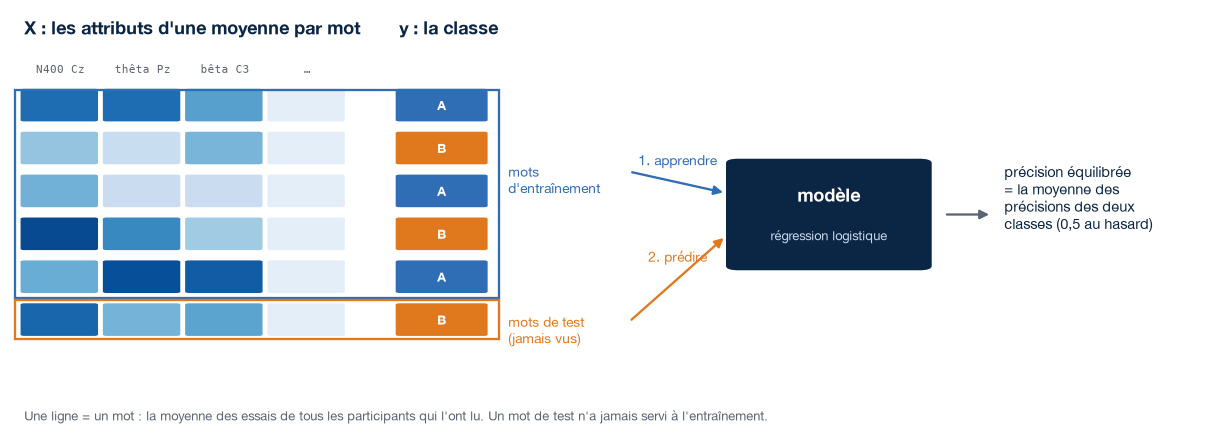

| Mot | Sens ici |
|---|---|
| attributs (**X**) | les colonnes choisies, une ligne par mot (sa moyenne), par exemple `n400_Cz` |
| étiquette (**y**) | ce qu'on veut deviner : 0 = A, 1 = B (pour H3 : HF ou LF) |
| entraînement / test | le modèle apprend sur des mots, et on le juge sur des mots **jamais vus** |
| précision équilibrée | la part de bonnes réponses dans chaque classe (A, B), puis la moyenne des deux : 0,5 au hasard, même si une classe a plus d'exemples. C'est la mesure de tout le notebook |

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> Un attribut

L'attribut de votre hypothèse à Cz (pour H3 : `n400_Cz`), une moyenne par mot.

In [ ]:
# ---- 1.1 X (moyennes par mot x attributs) et y (étiquettes) ; un découpage entraînement / test
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

COLONNE_H = f"{ATTRIBUT}_Cz"                       # l'attribut de votre hypothèse, à Cz
X, y, mots = moyenne_par_mot([COLONNE_H])
cz = ~np.isnan(X).any(axis=1)                     # les ERP où Cz est mesurée (sans valeurs manquantes, pour ce premier modèle)
X, y, mots = X[cz], y[cz], mots[cz]
print("X :", X.shape, f"| {A} :", (y == 0).sum(), f"| {B} :", y.sum())

X_entr, X_test, y_entr, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
modele = LogisticRegression(class_weight="balanced")   # balanced : les deux classes pèsent autant
modele.fit(X_entr, y_entr)                         # 1. apprendre
print("Exactitude sur le test : %.2f" % modele.score(X_test, y_test))  # 2. prédire des mots jamais vus

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> La validation croisée, et le hasard

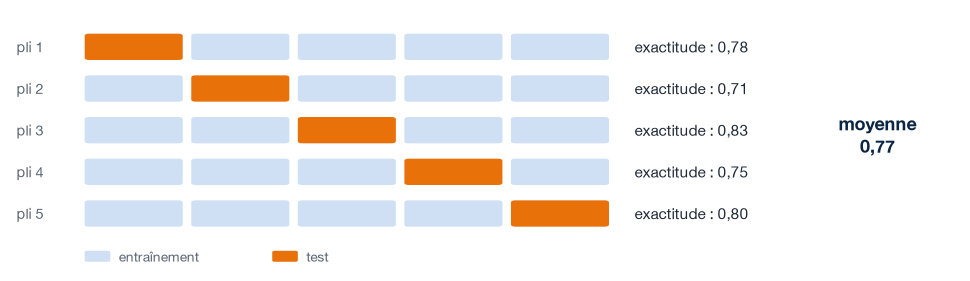

Un seul découpage dépend du hasard du tirage. La **validation croisée** (séance 5) coupe les mots en 10 parts, les **plis** : chaque pli
sert une fois de test, puis on fait la moyenne. `GroupKFold` garde ensemble les moyennes d'un même mot : un mot n'est jamais à la fois dans
l'entraînement et dans le test.

Le modèle de tout le notebook : **remplir** les valeurs manquantes, **standardiser** chaque attribut (moyenne 0, écart-type 1), puis la
régression logistique. `make_pipeline` garantit que tout est appris **sur l'entraînement seulement**. Le **test de permutation** mélange
les étiquettes 200 fois : il mesure ce que le hasard peut produire avec ces données (Combrisson et Jerbi, 2015).

In [ ]:
# ---- 1.2 Le modèle, la validation croisée en 10 plis (par mot), et deux références du hasard
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_score, cross_val_predict, permutation_test_score
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score


def nouveau_modele(C=1.0):
    """Remplir les NaN (moyenne d'entraînement), standardiser, régression logistique (C : partie 2)."""
    return make_pipeline(SimpleImputer(keep_empty_features=True), StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=3000))


plis = list(GroupKFold(n_splits=10, shuffle=True, random_state=0).split(X, y, groups=mots))   # un mot : un seul pli
scores = cross_val_score(nouveau_modele(), X, y, cv=plis, scoring="balanced_accuracy")
print("Précision équilibrée par pli :", np.round(scores, 2), "| moyenne : %.2f" % scores.mean())
print("Toujours la classe la plus fréquente : %.2f" % cross_val_score(DummyClassifier(), X, y, cv=plis, scoring="balanced_accuracy").mean())

score, scores_hasard, p = permutation_test_score(nouveau_modele(), X, y, cv=plis, n_permutations=200, random_state=0,
                                                 scoring="balanced_accuracy")
plt.figure(figsize=(7, 3))
plt.hist(scores_hasard, bins=20, color="#C3C9D2", label="étiquettes mélangées (200 fois)")
plt.axvline(score, color="#E8710A", lw=2.5, label=f"vraies étiquettes : {score:.2f}")
plt.axvline(np.percentile(scores_hasard, 95), color="#0B2545", lw=1, label="95 % du hasard")
plt.xlabel("précision équilibrée"); plt.ylabel("nombre"); plt.legend(frameon=False, fontsize=9)
plt.title(f"{COLONNE_H}, une moyenne par mot ({A} ou {B}) : p = {p:.3f}")
plt.show()

**Lire.** En gris, les scores du hasard (étiquettes mélangées) ; le trait noir en marque les 95 %. Le score des vraies étiquettes (orange)
le dépasse-t-il ? *Avec H3 (la version exécutée)* : 0,55, juste sur le trait des 95 % (p ≈ 0,055) : à la limite du hasard.

### <span style="background:#E8710A; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 2</span> À vous de compléter

Même évaluation avec l'attribut de **rythme** de votre hypothèse à Cz (`f"{RYTHME}_Cz"`, pour H3 : le thêta de 300 à 500 ms) au lieu
de son attribut ERP. Lequel distingue le mieux A et B ?

In [ ]:
# ---- Exercice
# X_r, y_r, mots_r = moyenne_par_mot([...])                                     # <--- à compléter
# print(f"{RYTHME} à Cz : %.2f" % cross_val_score(nouveau_modele(), X_r, y_r, cv=plis, scoring="balanced_accuracy").mean())

In [ ]:
#@title Solution (à consulter après avoir essayé)
X_r, y_r, mots_r = moyenne_par_mot([f"{RYTHME}_Cz"])
print(f"{RYTHME} à Cz : %.2f" % cross_val_score(nouveau_modele(), X_r, y_r, cv=GroupKFold(10, shuffle=True, random_state=0),
                                                groups=mots_r, scoring="balanced_accuracy").mean())
# (des plis refaits pour ces ERP : un mot sans mesure à Cz peut manquer)

## 2. Votre question : du plus simple au plus riche

<div style="margin:2px 0 8px 0; color:#5B6472;">Pour : <span style="color:#0B5CAD; font-weight:bold;">toutes les hypothèses</span></div>

<div style="border-left:5px solid #0B5CAD; background:#EEF3F9; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#0B5CAD;">Ce qui change avec votre hypothèse</b><br><ul style='margin:4px 0 0 0;'><li><b>La question</b> : HF ou LF (H2 à H5, H7, H8), assis ou marche (H1, H6, H10), rapide ou lent (H9).</li><li><b>Les deux attributs de H</b>, chacun dans sa région : sa composante de l'ERP et sa mesure de rythme (2.2, 2.3).</li><li><b>Les tranches de la fenêtre de H</b> : le décours seulement dans la fenêtre de votre composante (2.3).</li><li><b>Le zéro des temps</b> au décodage dans le temps (partie 4) : la tape pour la CPP (H9, H10), le mot sinon ; et les parties 3 et 5.</li><li>Les modèles « larges » (les 5 ERP, les décours sur 19 électrodes) ne dépendent que de la question : ils sont <b>les mêmes</b> pour les hypothèses d'une même question. Ce sont des références : votre hypothèse fait-elle mieux, ou moins bien ?</li></ul></div>

<div style="border-left:5px solid #E8710A; background:#FDF1E7; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#E8710A;">Hypothèse sur la posture (H1, H6, H10) ?</b><br>Faites d'abord la partie 3 : assis contre en marche, le modèle
reconnaît surtout le bruit de la marche. Les scores près de 1 de cette partie ne disent rien de la P200, de la P3 ou de la CPP.</div>

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> Deux outils : un score par pli, et une figure

`score_mots` refait la validation croisée en 10 plis (par mot) pour une liste de colonnes. Avec beaucoup de colonnes et 400 mots, le
modèle doit rester simple : `C = 0.01` par défaut (la régularisation, plus bas). `comparer` dessine une barre par modèle (la moyenne des
plis), un point par pli, et le **seuil du hasard** (trait orange) : avec ce nombre d'ERP prédits, un score au-delà a moins de 5 % de
chances d'être dû au hasard. Elle écrit aussi ce p (binomial, approché).

In [ ]:
# ---- 2.1 Une précision par pli, pour une liste de colonnes (la question et la posture de la cellule 0.2)
def score_mots(cols, question=QUESTION, posture=POSTURE, C=0.01):
    """Validation croisée en 10 plis sur les moyennes par mot : un mot de test n'a jamais servi à l'entraînement. Une précision par pli."""
    X_, y_, mots_ = moyenne_par_mot(cols, question, posture)
    plis_ = GroupKFold(n_splits=10, shuffle=True, random_state=0)
    s = pd.Series(cross_val_score(nouveau_modele(C), X_, y_, cv=plis_, groups=mots_, scoring="balanced_accuracy"))
    s.attrs["n"] = len(y_)                                       # le nombre d'ERP prédits (pour le seuil du hasard)
    return s


attribut_cz = score_mots([COLONNE_H])
print(f"{COLONNE_H} : {attribut_cz.round(2).to_list()} | moyenne {attribut_cz.mean():.2f}")

In [ ]:
#@title Fonction de figure : comparer des modèles (exécuter ; pas besoin de lire le code)
from scipy.stats import binom

RESULTATS = []          # tous les scores du notebook, pour le récapitulatif


def comparer(scores, titre):
    """Une barre par modèle (la moyenne des plis), un point par pli (ou par personne), et le seuil du hasard de chaque modèle."""
    noms = list(scores)
    fig, ax = plt.subplots(figsize=(8.5, 0.55 * len(noms) + 1.3))
    for j, nom in enumerate(noms):
        s = scores[nom]
        n = s.attrs.get("n", len(s))                              # le nombre d'exemples prédits
        seuil = binom.ppf(0.95, n, 0.5) / n
        p = binom.sf(round(s.mean() * n) - 1, n, 0.5)
        ax.barh(j, s.mean(), color="#0B5CAD" if s.mean() > seuil else "#9DB8DA", height=0.6, zorder=2)
        ax.scatter(s.to_numpy(), np.full(len(s), j), s=12, color="#0B2545", alpha=0.6, zorder=3)
        ax.plot([seuil, seuil], [j - 0.38, j + 0.38], color="#E8710A", lw=2, zorder=4)
        ax.text(1.005, j, f"{s.mean():.2f}".replace(".", ","), va="center", fontsize=10, color="#1F2937",
                transform=ax.get_yaxis_transform())
        print(f"{nom} : {s.mean():.3f} ({n} prédits ; p ≈ {p:.3f})")
        RESULTATS.append({"modèle": nom, "précision équilibrée": round(s.mean(), 3), "prédits": n, "p": round(p, 4)})
    ax.axvline(0.5, color="#5B6472", lw=1, zorder=1)
    ax.set_yticks(range(len(noms)), noms); ax.set_ylim(len(noms) - 0.5, -0.7)
    ax.set_xlim(0.3, 1.0); ax.set_xlabel("précision équilibrée (validation croisée) ; orange : le seuil du hasard (p < 0,05)")
    ax.set_title(titre, loc="left")
    plt.tight_layout(); plt.show()

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> Les stratégies A à E

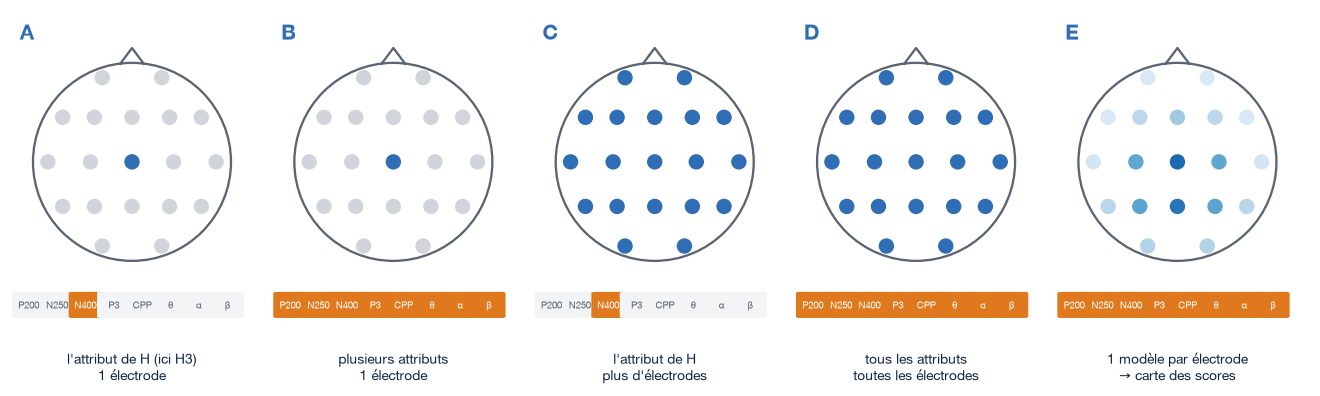

Du plus simple au plus riche : A et B à une électrode, C et D sur plus d'électrodes, E un modèle par électrode.

**A → B : combiner des attributs à une électrode (Cz).** Chaque attribut capte un aspect différent du signal. Les combiner aide-t-il ?

In [ ]:
# ---- 2.2 À Cz : l'attribut de l'hypothèse, puis des combinaisons (stratégies A et B)
modeles_cz = {
    f"{ATTRIBUT} (votre hypothèse, ERP)": [COLONNE_H],
    f"{RYTHME} (votre hypothèse, rythme)": [f"{RYTHME}_Cz"],
    "les 5 ERP": colonnes(ATTRIBUTS_ERP, ["Cz"]),
    "les 5 rythmes": colonnes(ATTRIBUTS_RYTHMES, ["Cz"]),
    "le décours ERP (14 tranches)": colonnes(DECOURS, ["Cz"]),
    "le décours des rythmes (24 tranches)": colonnes(TOUS_DECOURS_RYTHMES, ["Cz"]),
}
comparer({nom: score_mots(cols) for nom, cols in modeles_cz.items()}, f"{A} ou {B} : attributs de Cz")

**Lire.** Un attribut seul dépasse-t-il le seuil du hasard ? Une combinaison n'aide que si elle apporte une information **nouvelle**. *Avec H3 (la version exécutée)* : la N400 de Cz donne 0,55 (p ≈ 0,03) et le décours des rythmes de Cz 0,56 (p ≈ 0,01) ; le thêta seul s'en approche (0,54). Les 5 ERP et le décours ERP de Cz restent au hasard (0,49 et 0,51) : plus d'attributs n'aide pas toujours.

### <span style="background:#E8710A; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 2</span> À vous de compléter

Même comparaison à **Pz**, à l'arrière : complétez la liste des électrodes. Pz fait-il mieux ou moins bien que Cz ?

In [ ]:
# ---- Exercice
# modeles_pz = {"le décours, Pz": colonnes(DECOURS, [...])}                    # <--- à compléter
# comparer({nom: score_mots(cols) for nom, cols in modeles_pz.items()}, "Pz")

In [ ]:
#@title Solution (à consulter après avoir essayé)
modeles_pz = {"le décours, Pz": colonnes(DECOURS, ["Pz"]), "le décours, Cz": colonnes(DECOURS, ["Cz"])}
comparer({nom: score_mots(cols) for nom, cols in modeles_pz.items()}, "Pz contre Cz")

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> C → D : plus d'électrodes

On passe de Cz à la région de la composante (notebook 2), puis aux 19 électrodes, puis à tous les attributs. Entre parenthèses : le
nombre de colonnes.

In [ ]:
# ---- 2.3 Plus d'électrodes (stratégies C et D)
decours_19 = colonnes(DECOURS, CANAUX)
f0, f1 = FENETRES_ERP.get(ATTRIBUT, FENETRE_CPP)
tranches_h = [d for d, (t0, _) in DECOURS.items() if f0 - 1e-9 <= t0 < f1]            # les tranches ERP dans la fenêtre de H
bande_h, (g0, g1) = (ob.RYTHMES | ob.RYTHME_TAPE)[RYTHME]
tranches_r = [d for d in DECOURS_RYTHMES[bande_h] if g0 - 1e-9 <= int(d[len(bande_h):]) / 1000 < g1]   # les tranches de rythme
modeles_el = {
    f"{ATTRIBUT}, Cz (1)": [COLONNE_H],
    f"{ATTRIBUT}, sa région ({len(REGION)})": colonnes([ATTRIBUT], REGION),
    f"{ATTRIBUT}, 19 électrodes (19)": colonnes([ATTRIBUT], CANAUX),
    "les 5 ERP, 19 électrodes (95)": colonnes(ATTRIBUTS_ERP, CANAUX),
    "le décours ERP, 19 électrodes (266)": decours_19,
    f"le décours ERP dans la fenêtre de {ATTRIBUT} ({19 * len(tranches_h)})": colonnes(tranches_h, CANAUX),
    f"{RYTHME}, sa région ({len(REGION_RYTHME)})": colonnes([RYTHME], REGION_RYTHME),
    f"{RYTHME}, 19 électrodes (19)": colonnes([RYTHME], CANAUX),
    f"le décours de {bande_h} dans la fenêtre de {RYTHME} ({19 * len(tranches_r)})": colonnes(tranches_r, CANAUX),
    "le décours des rythmes, 19 électrodes (456)": colonnes(TOUS_DECOURS_RYTHMES, CANAUX),
}
modeles_el = {nom: cols for nom, cols in modeles_el.items() if cols}   # (la CPP et le bêta avant la tape n'ont pas de tranches)
comparer({nom: score_mots(cols) for nom, cols in modeles_el.items()}, f"{A} ou {B} : plus d'électrodes, et les décours")

**Lire.** Plus d'électrodes aide-t-il ? Et les décours, qui gardent la forme de l'onde ou du rythme ? L'information est-elle dans la
fenêtre de votre hypothèse, ou ailleurs (le décours entier fait-il mieux que la fenêtre de H) ? L'ERP et le rythme de votre hypothèse
font-ils aussi bien l'un que l'autre ? *Avec H3 (la version exécutée)* : côté ERP, oui : la N400 de sa région donne 0,58 (p ≈ 0,002) et le décours ERP des 19 électrodes 0,59 (p < 0,001) ; le décours dans la seule fenêtre de la N400 fait moins (0,55) : l'information déborde de la fenêtre de l'hypothèse. Côté rythmes, rien ne dépasse le seuil avec les deux postures réunies (0,43 à 0,53) : voir 2.5.

<div style="border-left:5px solid #0B5CAD; background:#EEF3F9; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#0B5CAD;">Notion : surapprentissage et régularisation</b><br>Avec beaucoup d'attributs et peu d'exemples, le modèle peut apprendre
par cœur le bruit de l'entraînement : c'est le <b>surapprentissage</b>. Le paramètre <code>C</code> de la régression logistique règle
la <b>régularisation</b> : plus <code>C</code> est petit, plus le modèle doit garder des poids faibles, donc rester simple.</div>

### <span style="background:#E8710A; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 2</span> À vous de compléter : la régularisation

Refaites le modèle « le décours, 19 électrodes » avec `C=0.0001`, `C=0.01` (le défaut) et `C=1`. Lequel s'en sort le mieux ?

In [ ]:
# ---- Exercice
# comparer({f"C = {c}": score_mots(decours_19, C=c) for c in [...]}, "Régularisation")      # <--- à compléter

In [ ]:
#@title Solution (à consulter après avoir essayé)
comparer({f"C = {c}": score_mots(decours_19, C=c) for c in [0.0001, 0.01, 1]}, "Régularisation (266 colonnes)")
# Avec 266 colonnes et 400 mots, un modèle trop libre (C grand) apprend le bruit ; trop contraint (C très petit), il n'apprend plus rien.

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> E : un modèle par électrode, une carte des scores

Pour chacune des 19 électrodes, un modèle avec son propre décours, puis la précision de chaque électrode sur la tête : **où** se
trouve l'information ? Est-ce dans la région de votre composante ? Environ 20 secondes.

In [ ]:
# ---- 2.4 19 modèles (un par électrode), puis la carte
info = mne.create_info(CANAUX, sfreq=100, ch_types="eeg")
info.set_montage("standard_1020")


def carte_scores(mesures, question=QUESTION, posture=POSTURE):
    """La précision moyenne des plis, avec un modèle par électrode (ses propres attributs)."""
    return np.array([score_mots(colonnes(mesures, [c]), question, posture).mean() for c in CANAUX])


carte = carte_scores(DECOURS)
fig, ax = plt.subplots(figsize=(4.2, 4))
im, _ = mne.viz.plot_topomap(carte, info, axes=ax, cmap="Reds", vlim=(0.5, max(carte.max(), 0.55)), show=False, names=CANAUX)
fig.colorbar(im, ax=ax, shrink=0.75, label="précision équilibrée")
ax.set_title(f"{A} ou {B} : un modèle (le décours) par électrode")
plt.show()
print("Les 5 meilleures électrodes :", pd.Series(carte, index=CANAUX).sort_values(ascending=False).head(5).round(2).to_dict())

**Lire.** Les meilleures électrodes sont-elles dans la région de votre composante ? Une information à l'avant (Fp1, Fp2 : les yeux) ou
partout à la fois (le bruit) serait suspecte. *Avec H3 (la version exécutée)* : les meilleures sont P3 (0,58), Fp1 (0,57) et C4 (0,56). Fp1, tout à l'avant, peut venir des yeux : à vérifier (les essais sans clignement, notebook 2).

### <span style="background:#7C3AED; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 3</span> À vous de construire : une carte par famille d'attributs

Objectif : la même carte avec le **décours des rythmes**, à côté de la carte du décours ERP. Les régions informatives sont-elles
les mêmes ?

<div style="border-left:5px solid #7C3AED; background:#F5F0FF; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#7C3AED;">Indices</b><br><ul style='margin:4px 0 0 0;'><li><code>carte_scores(TOUS_DECOURS_RYTHMES)</code> donne les 19 précisions.</li><li>Une figure à deux panneaux : <code>fig, axes = plt.subplots(1, 2)</code>, puis <code>axes=axes[0]</code> et <code>axes=axes[1]</code>.</li><li>Gardez la même échelle de couleurs (<code>vlim=(0.5, 0.65)</code>) pour comparer.</li><li>Documentation : <a href='https://mne.tools/stable/generated/mne.viz.plot_topomap.html'>plot_topomap</a>.</li></ul></div>

In [ ]:
# ---- Votre cellule

In [ ]:
#@title Solution (à consulter après avoir essayé)
cartes = {"le décours ERP": carte, "le décours des rythmes (θ, α, β)": carte_scores(TOUS_DECOURS_RYTHMES)}
fig, axes = plt.subplots(1, 2, figsize=(8, 3.8))
for ax, (nom, c) in zip(axes, cartes.items()):
    im, _ = mne.viz.plot_topomap(c, info, axes=ax, cmap="Reds", vlim=(0.5, 0.65), show=False)
    ax.set_title(nom)
fig.colorbar(im, ax=axes, shrink=0.7, label="précision équilibrée")
plt.show()

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> Une famille d'attributs à la fois (toutes les électrodes)

La carte montre **où** ; ici, quelle famille apporte le plus quand on garde les 19 électrodes ?

In [ ]:
# ---- 2.5 Chaque famille, sur les 19 électrodes
familles = {
    "les 5 ERP, 19 électrodes (95)": colonnes(ATTRIBUTS_ERP, CANAUX),
    "les 5 rythmes, 19 électrodes (95)": colonnes(ATTRIBUTS_RYTHMES, CANAUX),
    "le décours ERP, 19 électrodes (266)": decours_19,
    "le décours des rythmes, 19 électrodes (456)": colonnes(TOUS_DECOURS_RYTHMES, CANAUX),
    "les deux décours (722)": decours_19 + colonnes(TOUS_DECOURS_RYTHMES, CANAUX),
}
for posture in ("les deux", "assis"):                       # les deux postures, puis les essais assis seulement
    comparer({nom: score_mots(cols, posture=posture) for nom, cols in familles.items()},
             f"{A} ou {B} : familles d'attributs (postures : {posture})")

**Lire.** Les ERP et les rythmes portent-ils la même information, ou des informations qui s'ajoutent ? Comparez les deux figures : en
marche, le bruit des pas s'ajoute surtout à la puissance des rythmes (notebook 3, partie 1), et leur information s'y perd. *Avec H3 (la version exécutée)* : avec les deux postures, les ERP portent l'information (0,57 à 0,59), les rythmes non (0,50). **Assis seulement**, les 5 rythmes font même mieux que les 5 ERP (0,64 et 0,60, p < 0,001), et les deux décours ensemble 0,62 : l'information des rythmes existe, mais le bruit de la marche la cache.

### <span style="background:#E8710A; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 2</span> 2.6 À explorer (recommandé) : un essai, une moyenne par mot, une moyenne par personne

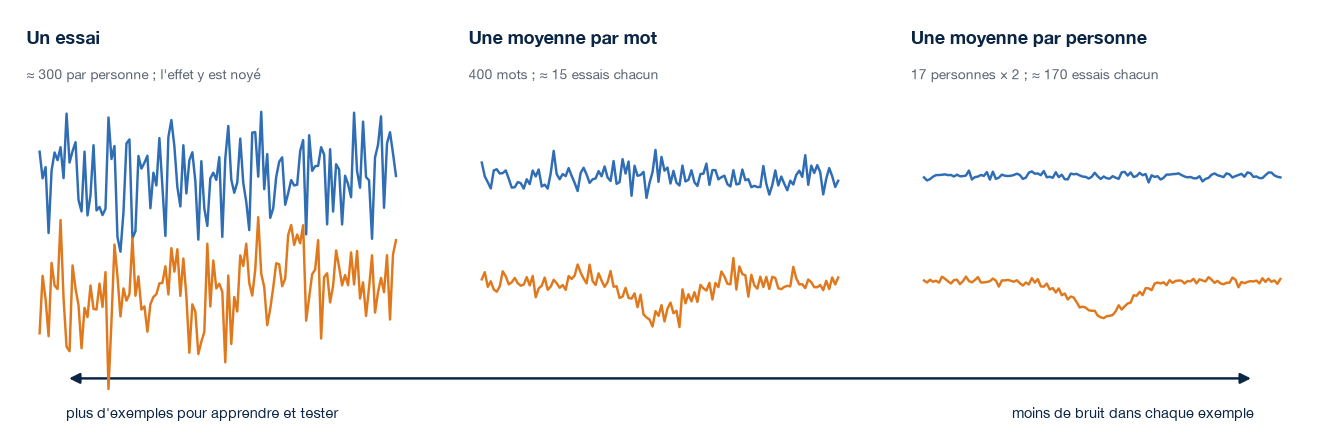

Le même modèle (le décours, 19 électrodes) sur trois unités. Plus on moyenne d'essais, moins chaque exemple est bruité, mais moins il y a
d'exemples pour apprendre et pour tester :

| Unité | Exemples | Essais par exemple | Le test |
|---|---|---|---|
| un essai | ≈ 300 par personne | 1 | intra-sujet : 5 plis dans chaque personne |
| une moyenne par mot (le défaut) | 400 mots | ≈ 15 | des mots nouveaux (10 plis) |
| une moyenne par personne | 17 personnes × 2 | ≈ 170 | une personne nouvelle (17 plis de 2 moyennes) |

La cellule suivante donne les deux autres unités. Complétez la comparaison. Puis refaites-la avec `posture="assis"` : en marche, chaque
essai est deux fois plus bruité (et l'effet de fréquence n'y est pas le même, H4).

In [ ]:
#@title Les deux autres unités : un essai, une moyenne par personne (exécuter ; pas besoin de lire le code)
from sklearn.model_selection import StratifiedKFold, LeaveOneGroupOut


def score_essais(cols, question=QUESTION, posture=POSTURE, C=0.01):
    """Un essai = un exemple ; validation croisée en 5 plis dans chaque personne. Une précision par personne."""
    resultats, n = {}, []
    for sujet, essais in df.groupby("participant"):
        essais, y_ = essais_et_etiquettes(essais, question, posture)
        if min(y_.sum(), (y_ == 0).sum()) < 20:                            # trop peu d'essais dans une classe
            continue
        plis_ = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
        resultats[sujet] = cross_val_score(nouveau_modele(C), essais[cols].to_numpy(), y_, cv=plis_, scoring="balanced_accuracy").mean()
        n.append(len(y_))
    s = pd.Series(resultats)
    s.attrs["n"] = int(np.median(n))                                        # le seuil du hasard d'une personne
    return s


def score_personnes(cols, question=QUESTION, posture=POSTURE, C=0.01):
    """Une moyenne par personne et par condition ; on entraîne sur 16 personnes, on teste sur la 17e. Une précision par personne."""
    essais, y_ = essais_et_etiquettes(dfz, question, posture)
    erp = essais[cols].groupby([essais["participant"], pd.Series(y_, index=essais.index, name="y")]).mean()
    personnes = erp.index.get_level_values("participant").to_numpy()
    s = pd.Series(cross_val_score(nouveau_modele(C), erp.to_numpy(), erp.index.get_level_values("y").to_numpy(), cv=LeaveOneGroupOut(),
                                  groups=personnes, scoring="balanced_accuracy"), index=np.unique(personnes))
    s.attrs["n"] = len(erp)
    return s

In [ ]:
# ---- Exercice : les trois unités, sur le décours des 19 électrodes
# trois = {"un essai (intra-sujet)": score_essais(decours_19),
#          "une moyenne par mot (nouveaux mots)": ...,                                       # <--- à compléter
#          "une moyenne par personne (nouvelle personne)": ...}                              # <--- à compléter
# comparer(trois, f"{A} ou {B} : trois unités")

In [ ]:
#@title Solution (à consulter après avoir essayé)
for posture in ("les deux", "assis"):
    trois = {"un essai (intra-sujet)": score_essais(decours_19, posture=posture),
             "une moyenne par mot (nouveaux mots)": score_mots(decours_19, posture=posture),
             "une moyenne par personne (nouvelle personne)": score_personnes(decours_19, posture=posture)}
    comparer(trois, f"{A} ou {B} : trois unités (postures : {posture})")

**Lire.** Où le modèle dépasse-t-il le plus nettement son seuil du hasard ? Une moyenne par personne donne un score élevé, mais sur 34 exemples
seulement : chaque erreur coûte 3 points. Que gagne-t-on, ou perd-on, à garder seulement les essais assis ? *Avec H3 (la version exécutée)* : postures réunies : un essai 0,51 (hasard), une moyenne par mot 0,59 (p < 0,001), une moyenne par personne 0,68 (p ≈ 0,03, sur 34). Assis seulement : 0,53, 0,57 et **0,82** (28 moyennes de personne sur 34 bien classées).

## 3. Trois pièges

<div style="margin:2px 0 8px 0; color:#5B6472;">Pour : <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H1</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H6</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H10</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H9</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H2</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H3</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H7</span></div>

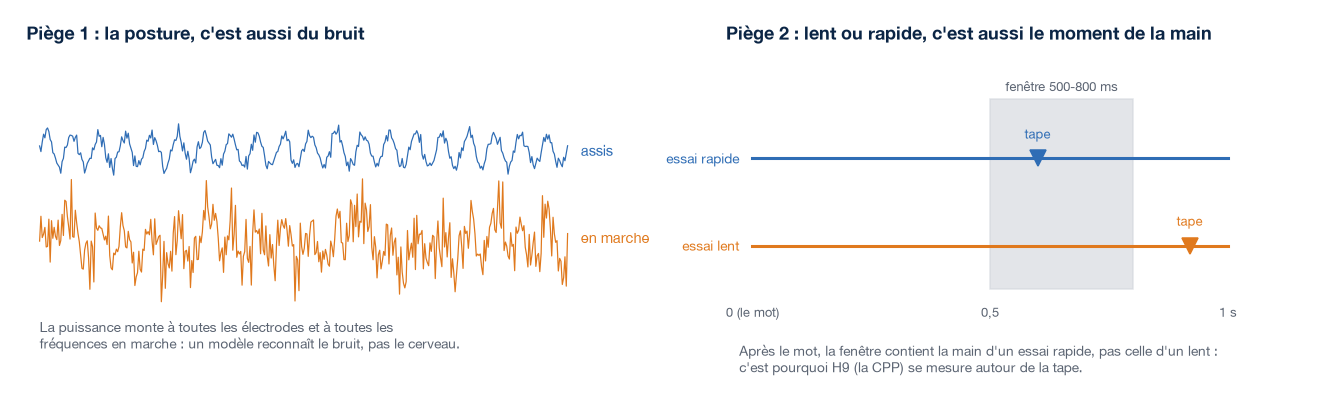

Un modèle utilise tout ce qui distingue les deux classes, pas seulement le cerveau. Trois cas dans ces données.

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> Piège 1 : assis ou en marche ? (H1, H6, H10)

Les mêmes outils, pour la posture (une moyenne par mot et par posture) : le décours des rythmes, le décours ERP, le bêta à une seule
électrode, puis une carte des rythmes par électrode.

In [ ]:
# ---- 3.1 La posture : les rythmes, l'ERP, et une carte des rythmes par électrode
comparer({"le décours des rythmes, 19 électrodes": score_mots(colonnes(TOUS_DECOURS_RYTHMES, CANAUX), "posture"),
          "le décours ERP, 19 électrodes": score_mots(decours_19, "posture"),
          "β à Cz seulement": score_mots(colonnes(DECOURS_RYTHMES["beta"], ["Cz"]), "posture")},
         "Assis ou en marche")
carte_post = carte_scores(TOUS_DECOURS_RYTHMES, "posture")
fig, ax = plt.subplots(figsize=(4.2, 4))
im, _ = mne.viz.plot_topomap(carte_post, info, axes=ax, cmap="Reds", vlim=(0.5, 1.0), show=False, names=CANAUX)
fig.colorbar(im, ax=ax, shrink=0.75, label="précision équilibrée")
ax.set_title("Assis ou en marche : un modèle (rythmes) par électrode")
plt.show()

**Lire.** Presque parfait, et presque toutes les électrodes y arrivent : ce n'est pas une région du cerveau. En marche, les électrodes
sèches bougent à chaque pas, et la puissance monte à toutes les électrodes et à toutes les fréquences (notebook 3, partie 1). Le modèle
reconnaît le bruit de la marche. *Avec H3 (la version exécutée)* : 1,00 avec le décours des rythmes, déjà 0,97 avec le bêta de Cz seul, et 0,70 avec le décours ERP.

### <span style="background:#E8710A; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 2</span> À vous de compléter : un seul nombre, le bruit

Construisez **une seule** colonne, `bruit` = la moyenne de la puissance du bêta (son décours, `DECOURS_RYTHMES["beta"]`) sur les 19
électrodes (en ignorant les NaN), et évaluez-la seule pour assis/marche.

In [ ]:
# ---- Exercice
# dfz["bruit"] = dfz[colonnes(DECOURS_RYTHMES[...], CANAUX)].mean(axis=1)   # <--- à compléter
# comparer({"bruit (1 colonne)": score_mots(["bruit"], "posture")}, "Assis ou en marche : le bruit")

In [ ]:
#@title Solution (à consulter après avoir essayé)
dfz["bruit"] = dfz[colonnes(DECOURS_RYTHMES["beta"], CANAUX)].mean(axis=1)
comparer({"bruit (1 colonne)": score_mots(["bruit"], "posture"),
          "le décours des rythmes, 19 électrodes": score_mots(colonnes(TOUS_DECOURS_RYTHMES, CANAUX), "posture")},
         "Assis ou en marche : le bruit")
# Un seul nombre, qui ne dit rien d'une région du cerveau, suffit presque : le bruit de la marche.

<div style="border-left:5px solid #E8710A; background:#FDF1E7; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#E8710A;">Attention : un bon score ne prouve pas qu'on décode le cerveau</b><br>Un modèle utilise <b>tout ce qui distingue les
classes</b>, y compris un artefact : c'est l'effet « Clever Hans » (Lapuschkin et al., 2019). À la séance 5, c'étaient les yeux ; ici,
c'est le bruit de la marche. Pour H1, H6 et H10, le décodage de la posture ne teste donc pas l'hypothèse : les notebooks 2 et 3 la testent,
avec une région et une fenêtre choisies d'avance. Pour s'en protéger : regarder <b>où</b> et <b>quand</b> le modèle trouve l'information,
et tester l'artefact connu seul.</div>

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> Piège 2 : lent ou rapide, c'est aussi le moment de la main (H9)

**La tape** : le toucher de la tablette par lequel le participant répond. Dans un essai rapide, elle arrive souvent **pendant** la
fenêtre 500-800 ms après le mot ; dans un essai lent, après. Après le mot, un modèle peut donc reconnaître la présence de la main, pas une
CPP différente. C'est pourquoi H9 se mesure **autour de la tape** (`cpp`). On compare les deux (une moyenne par mot et par vitesse) :

In [ ]:
# ---- 3.2 Rapide ou lent : après le mot (p3) ou avant la tape (cpp) ?
comparer({"p3 : 500-800 ms après le mot (19 électrodes)": score_mots(colonnes(["p3"], CANAUX), "tr"),
          "cpp : les 500 ms avant la tape (19 électrodes)": score_mots(colonnes(["cpp"], CANAUX), "tr")},
         "Rapide ou lent : le moment de la main")

**Lire.** Si le décodage après le mot est bien meilleur qu'avant la tape, il vient sans doute en partie de la main, pas seulement de la
décision. *Avec H3 (la version exécutée)* : 0,53 après le mot comme avant la tape (p ≈ 0,02 et 0,03) : à peine au-dessus du hasard, et sans différence entre les deux ; ici, rien ne montre que le moment de la main aide le modèle.

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> Piège 3 : le nombre d'essais (H2, H3, H7)

Les mots rares (LF) ont moins de bonnes réponses que les fréquents (73 % contre 96 %) : leurs moyennes comptent moins d'essais, et
elles sont donc plus **bruitées**. Ce bruit n'a rien à voir avec la lecture du mot, mais un modèle peut s'en servir. Trois modèles :
le nombre d'essais seul (une colonne), puis une **forêt d'arbres** (un modèle non linéaire, qui sait reconnaître une moyenne plus
bruitée) sur le décours ERP, avec toutes les moyennes, puis avec le même nombre d'essais dans chaque moyenne (`EGALISER`, 0.4).

In [ ]:
# ---- 3.3 Le nombre d'essais de chaque moyenne : un indice que le modèle peut utiliser (environ 30 secondes)
from sklearn.ensemble import RandomForestClassifier

essais_q, y_q = essais_et_etiquettes(dfz, QUESTION, POSTURE)
n_essais = essais_q.groupby([essais_q["stimulus"], pd.Series(y_q, index=essais_q.index, name="y")]).size()   # chaque moyenne
print(f"Essais par moyenne (sans égaliser) : {A} {n_essais.xs(0, level='y').mean():.1f}, {B} {n_essais.xs(1, level='y').mean():.1f}")
plis_n = GroupKFold(n_splits=10, shuffle=True, random_state=0)
seul = pd.Series(cross_val_score(LogisticRegression(class_weight="balanced"), n_essais.to_numpy()[:, None], n_essais.index.get_level_values("y"),
                                 cv=plis_n, groups=n_essais.index.get_level_values("stimulus"), scoring="balanced_accuracy"))
seul.attrs["n"] = len(n_essais)


def score_foret(egaliser):
    """Une forêt d'arbres sur le décours ERP (19 électrodes), avec ou sans le même nombre d'essais dans chaque moyenne."""
    X_, y_, m_ = ob.moyenne_par_mot(dfz, decours_19, QUESTION, POSTURE, egaliser)
    foret = make_pipeline(SimpleImputer(keep_empty_features=True), StandardScaler(),
                          RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0))
    s_ = pd.Series(cross_val_score(foret, X_, y_, cv=plis_n, groups=m_, scoring="balanced_accuracy"))
    s_.attrs["n"] = len(y_)
    return s_


comparer({"le nombre d'essais seul (1 colonne)": seul, "une forêt, toutes les moyennes": score_foret(False),
          "une forêt, le même nombre d'essais": score_foret(True)}, f"{A} ou {B} : le nombre d'essais")

**Lire.** Si le nombre d'essais seul décode bien, et si la forêt perd beaucoup quand chaque moyenne a le même nombre d'essais, elle
reconnaissait le bruit, pas le cerveau. C'est pourquoi le notebook égalise par défaut. *Avec H3 (la version exécutée)* : les mots rares ont 11,3 essais en moyenne, les fréquents 14,9 : le nombre d'essais seul devine HF ou LF à 0,75. La forêt fait 0,68 avec toutes les moyennes, mais 0,57 avec le même nombre d'essais : une bonne part de son score venait du bruit, pas du cerveau.

## 4. Décoder dans le temps

<div style="margin:2px 0 8px 0; color:#5B6472;">Pour : <span style="color:#0B5CAD; font-weight:bold;">toutes les hypothèses</span></div>

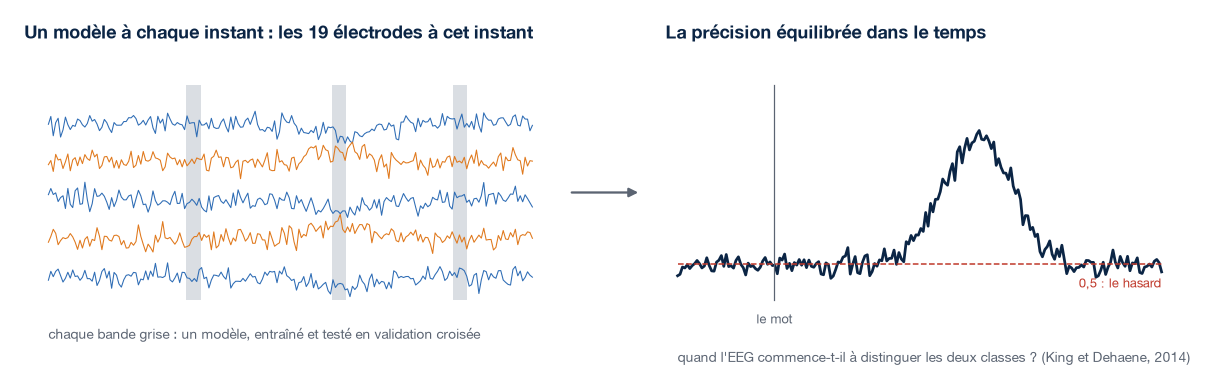

Les parties 2 et 3 disaient **où** ; on cherche maintenant **quand**. Au lieu des fenêtres choisies d'avance, **un modèle à chaque instant**
(toutes les 20 ms), sur les 19 électrodes à cet instant (King et Dehaene, 2014), toujours sur des moyennes par mot. `mne.decoding.SlidingEstimator`
fait la boucle ; le score reste la précision équilibrée (0,5 = le hasard). Le zéro des temps est le mot, ou la tape pour la CPP (H9, H10).
Environ 1 minute.

- Chaque électrode est centrée-réduite dans chaque personne, puis les essais d'un mot sont moyennés (comme en 0.4).
- Une électrode jamais mesurée pour un mot reçoit 0, la moyenne de la personne (`SlidingEstimator` refuse les NaN).

In [ ]:
# ---- 4.1 Les moyennes par mot instant par instant, puis un modèle par instant
from mne.decoding import SlidingEstimator, cross_val_multiscore

CENTRE = "tape" if ATTRIBUT == "cpp" else "mot"          # le zéro des temps : la tape pour la CPP, le mot sinon
X_t, y_t, mots_t, temps = ob.moyennes_temps(DOSSIER, SUJETS, CENTRE, QUESTION, POSTURE, EGALISER)   # mots x électrodes x instants (50 Hz)
decodeur = SlidingEstimator(nouveau_modele(), scoring="balanced_accuracy")
courbes = cross_val_multiscore(decodeur, X_t, y_t, cv=GroupKFold(n_splits=10, shuffle=True, random_state=0), groups=mots_t)   # plis x instants

plt.figure(figsize=(9, 3.6))
plt.plot(temps, courbes.T, color="#C3C9D2", lw=0.8)
plt.plot(temps, courbes.mean(axis=0), color="#0B2545", lw=2.5, label="moyenne des 10 plis")
plt.axhline(0.5, color="#5B6472", lw=1); plt.axvline(0, color="#5B6472", lw=1)
plt.axvspan(*(FENETRE_CPP if CENTRE == "tape" else FENETRES_ERP[ATTRIBUT]), color="#DBEAFE", zorder=0, label=f"fenêtre de {ATTRIBUT}")
plt.xlabel(f"Temps depuis {'la tape' if CENTRE == 'tape' else 'le mot'} (s)"); plt.ylabel("précision équilibrée"); plt.ylim(0.3, 0.85)
plt.title(f"{A} ou {B}, instant par instant ({len(y_t)} moyennes par mot)"); plt.legend(frameon=False, fontsize=8)
plt.show()

**Lire.** Avant le zéro (le mot), la courbe doit rester à 0,5. Monte-t-elle ensuite, et dans la fenêtre de votre composante ? *Avec H3 (la version exécutée)* : la courbe oscille autour de 0,5, y compris avant le mot (jusqu'à 0,58 vers −0,18 s : c'est l'ampleur du hasard ici) ; elle dépasse un peu 0,55 vers 0,2-0,25 s et vers 0,45 s, sans montée nette et durable : instant par instant, l'information est trop faible.

### <span style="background:#7C3AED; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 3</span> À vous de construire : la généralisation dans le temps

Objectif : entraîner à chaque instant et tester à **tous** les instants (King et Dehaene, 2014). Une diagonale étroite = un code qui change
vite ; un carré = un même code qui dure.

<div style="border-left:5px solid #7C3AED; background:#F5F0FF; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#7C3AED;">Indices</b><br><ul style='margin:4px 0 0 0;'><li><code>from mne.decoding import GeneralizingEstimator</code> ; <code>GeneralizingEstimator(nouveau_modele(), scoring='balanced_accuracy')</code>.</li><li>Les données sont déjà là : <code>X_t</code>, <code>y_t</code>, <code>mots_t</code> (cellule 4.1).</li><li><code>cross_val_multiscore(..., cv=GroupKFold(...), groups=mots_t)</code> rend (plis × instants d'entraînement × instants de test) : moyennez sur les plis.</li><li><code>plt.imshow(moyenne, origin='lower', extent=[temps[0], temps[-1], temps[0], temps[-1]], cmap='RdBu_r', vmin=0.4, vmax=0.6)</code>.</li><li>Documentation : <a href='https://mne.tools/stable/auto_tutorials/machine-learning/50_decoding.html'>décodage avec MNE</a>.</li></ul></div>

In [ ]:
# ---- Votre cellule

In [ ]:
#@title Solution (à consulter après avoir essayé)
from mne.decoding import GeneralizingEstimator

gen = GeneralizingEstimator(nouveau_modele(), scoring="balanced_accuracy")
moyenne = cross_val_multiscore(gen, X_t, y_t, cv=GroupKFold(n_splits=10, shuffle=True, random_state=0), groups=mots_t).mean(axis=0)
plt.figure(figsize=(5, 4.3))
plt.imshow(moyenne, origin="lower", extent=[temps[0], temps[-1], temps[0], temps[-1]], cmap="RdBu_r", vmin=0.4, vmax=0.6)
plt.colorbar(label="précision équilibrée")
plt.axvline(0, color="k", lw=0.8); plt.axhline(0, color="k", lw=0.8)
plt.xlabel("instant de test (s)"); plt.ylabel("instant d'entraînement (s)"); plt.title("Généralisation dans le temps")
plt.show()

## 5. La posture et le comportement

### 5.1 L'effet change-t-il en marche ?

<div style="margin:2px 0 8px 0; color:#5B6472;">Pour : <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H4</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H8</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H10</span></div>

Les hypothèses d'interaction demandent si l'effet de fréquence (HF ou LF) change en marche. Côté décodage : avec les moyennes par mot faits
des seuls essais assis, puis des seuls essais en marche, le modèle distingue-t-il HF et LF aussi bien ? Et un modèle appris sur les ERP
assis **reconnaît-il** les ERP en marche de mots nouveaux (le **transfert**) ? Si l'effet est le même dans les deux postures, le transfert
devrait marcher presque aussi bien. Ici avec le décours des 19 électrodes.

In [ ]:
# ---- 5.1 HF ou LF : assis, en marche, et d'une posture à l'autre
from sklearn.model_selection import KFold


def score_transfert(cols, de="assis", vers="marche", C=0.01):
    """Un modèle appris sur les moyennes par mot d'une posture, testé sur les ERP de l'autre posture, pour des mots nouveaux."""
    X_de, y_de, m_de = moyenne_par_mot(cols, "frequence", de)
    X_vers, y_vers, m_vers = moyenne_par_mot(cols, "frequence", vers)
    liste_mots, scores_ = np.unique(m_de), []
    for entr, test in KFold(n_splits=10, shuffle=True, random_state=0).split(liste_mots):
        e, t = np.isin(m_de, liste_mots[entr]), np.isin(m_vers, liste_mots[test])
        modele = nouveau_modele(C).fit(X_de[e], y_de[e])
        scores_.append(balanced_accuracy_score(y_vers[t], modele.predict(X_vers[t])))
    s = pd.Series(scores_)
    s.attrs["n"] = len(y_vers)
    return s


comparer({"assis (validation croisée)": score_mots(decours_19, "frequence", "assis"),
          "en marche (validation croisée)": score_mots(decours_19, "frequence", "marche"),
          "appris assis, testé en marche": score_transfert(decours_19, "assis", "marche"),
          "appris en marche, testé assis": score_transfert(decours_19, "marche", "assis")},
         "HF ou LF (le décours, 19 électrodes) : assis, en marche, d'une posture à l'autre")

**Lire.** Le décodage est-il plus faible en marche ? Attention : le bruit de la marche baisse la précision **même si** le cerveau traite
les mots de la même façon. Le test de l'interaction reste celui du notebook 2 (partie 5). *Avec H3 (la version exécutée)* : 0,57 assis (p ≈ 0,006), 0,51 en marche (hasard) ; le transfert reste au hasard (0,51 et 0,52). Cela va dans le sens de H4 et H8, mais le bruit de la marche suffit à l'expliquer.

### 5.2 Le décodage suit-il le comportement ?

<div style="margin:2px 0 8px 0; color:#5B6472;">Pour : <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H5</span></div>

H5 porte sur les participants ; ici, la même idée à l'échelle des **mots**. Pour chaque mot, le modèle (appris sans lui) donne un score :
au-dessus de 0, il penche vers LF. Les mots que l'EEG « classe » le plus comme rares sont-ils aussi ceux qu'on reconnaît le plus
lentement ? On regarde le lien **dans chaque classe** (sinon il viendrait seulement de la différence entre HF et LF).

In [ ]:
# ---- 5.2 Le score de chaque mot (appris sans lui) et son TR moyen
X5, y5, mots5 = moyenne_par_mot(decours_19, "frequence")
plis5 = GroupKFold(n_splits=10, shuffle=True, random_state=0)
penchant = cross_val_predict(nouveau_modele(0.01), X5, y5, cv=plis5, groups=mots5, method="decision_function")   # > 0 : vers LF
tr_mot = df.groupby("stimulus")["tr_ms"].mean().loc[mots5].to_numpy()          # le TR moyen de chaque mot (bonnes réponses)
plt.figure(figsize=(5.5, 4))
for classe, nom, couleur in ((0, "HF", "#2f6db5"), (1, "LF", "#e0791d")):
    r, p = stats.pearsonr(penchant[y5 == classe], tr_mot[y5 == classe])
    plt.scatter(penchant[y5 == classe], tr_mot[y5 == classe], s=10, color=couleur, alpha=0.6, label=f"{nom} : r = {r:.2f}, p = {p:.3f}")
    print(f"{nom} : r = {r:.2f}, p = {p:.3f} ({(y5 == classe).sum()} mots)")
plt.axvline(0, color="#5B6472", lw=1)
plt.xlabel("score du modèle (> 0 : vers LF)"); plt.ylabel("TR moyen du mot (ms)"); plt.legend(frameon=False, fontsize=8)
plt.show()

**Lire.** Dans chaque classe, les mots que le modèle juge « plus rares » sont-ils reconnus plus lentement ? *Avec H3 (la version exécutée)* : pas de lien : r = 0,08 (HF) et 0,07 (LF), p > 0,25.

## 6. Récapitulatif

### <span style="background:#0B5CAD; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Type 1</span> Tous les modèles du notebook

Chaque modèle dessiné par `comparer`, une ligne par nom (les modèles des solutions n'y sont que si vous les avez exécutées).

In [ ]:
# ---- 6.1 Les scores de tous les modèles évalués dans ce notebook
recap = pd.DataFrame(RESULTATS).drop_duplicates("modèle", keep="last")
recap.sort_values("précision équilibrée", ascending=False).reset_index(drop=True)

| Votre question | Hypothèses | Ce que le décodage ajoute | Attention |
|---|---|---|---|
| A ou B | H2, H3, H7, H9 | **où** (2.4) et **quand** (4) se trouve l'information, sans fenêtre ni région choisies d'avance ; l'ERP **et** les rythmes (2.5) | dites l'unité (une moyenne par mot) et comparez au seuil du hasard ; les rythmes, surtout assis |
| Assis ou en marche | H1, H6, H10 | rien sur la composante : le modèle reconnaît le bruit (3.1) | ne pas le présenter comme un effet du cerveau |
| L'effet change-t-il en marche ? | H4, H8, H10 | le décodage dans chaque posture, et le transfert (5.1) | le bruit baisse la précision en marche, même sans changement du cerveau |
| Le comportement | H5 | le lien mot par mot entre le score du modèle et le TR (5.2) | exploratoire |

<div style="border-left:5px solid #15803D; background:#ECF8EF; color:#1F2937; padding:10px 16px; border-radius:6px; margin:8px 0;"><b style="color:#15803D;">À retenir</b><br><ul style='margin:4px 0 0 0;'><li>Toujours tester sur des exemples <b>jamais vus</b> : ici, des mots nouveaux (validation croisée par mot), et comparer au <b>hasard</b>.</li><li>Un essai seul est trop bruité pour un petit effet ; une moyenne (par mot, par personne) l'est moins, mais il y a moins d'exemples (2.6).</li><li>Plus d'attributs n'est pas toujours mieux : il faut une information nouvelle, et un modèle régularisé.</li><li>Un modèle par électrode (ou par instant) montre <b>où</b> (ou <b>quand</b>) est l'information : c'est ainsi qu'on vérifie qu'il décode le cerveau.</li><li>Un score élevé peut venir d'un artefact (la marche, le moment de la main) : testez l'artefact connu seul.</li><li>Le décodage complète les tests des notebooks 2 et 3 ; il ne les remplace pas.</li></ul></div>

## 7. Défis (points bonus)

Pour les groupes qui veulent aller plus loin : sept défis, avec les **outils de ce notebook** (`score_mots`, `carte_scores`, `comparer`,
`colonnes`). Les quatre premiers répondent aux défis du notebook 2 ; le cinquième, au notebook 3 ; les deux derniers portent sur le
modèle lui-même. Il n'y a pas de solution : c'est votre
travail. Pour chacun, présentez dans les **annexes du rapport** :

1. la question, et pourquoi elle compte pour votre hypothèse ;
2. ce que vous avez changé (les colonnes, la question, la posture) ;
3. le résultat (la précision et son p, ou une figure), et votre interprétation en deux ou trois phrases.

### <span style="background:#B45309; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Défi</span> A. Le mot, ou la réponse ?

<div style="margin:2px 0 8px 0; color:#5B6472;">Pour : <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H6</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H7</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H8</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H9</span></div>

**La question.** Le défi A du notebook 2, côté décodage. Les mots rares sont reconnus plus lentement : la réponse arrive plus tard. Un
modèle qui décode après le mot (500-800 ms) peut reconnaître le **moment de la réponse** plutôt que le traitement du mot. On compare avec
les 500 ms **avant la tape**, où la réponse est au même moment pour tous les essais.

**Comment.** Avec `comparer`, deux modèles sur les 19 électrodes : `colonnes(["p3"], CANAUX)` (après le mot) et `colonnes(["cpp"], CANAUX)`
(avant la tape), pour votre question (partie 3.2 : la même idée pour rapide ou lent).

**À rapporter.** Les deux précisions et leur p. Si l'information disparaît avant la tape, que dit-elle de votre hypothèse ?

In [ ]:
# ---- Défi A : votre cellule (gardez-y les résultats que vous rapportez)

### <span style="background:#B45309; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Défi</span> B. Un contrôle positif : un effet connu

<div style="margin:2px 0 8px 0; color:#5B6472;">Pour : <span style="color:#0B5CAD; font-weight:bold;">toutes les hypothèses</span></div>

**La question.** Le défi B du notebook 2, côté décodage. Le modèle trouve-t-il un effet connu, les pseudo-mots contre les mots ? S'il le
trouve, un score au hasard pour votre hypothèse est plus crédible.

**Comment.**

1. Dans 0.2, ajoutez la ligne `QUESTION, ATTRIBUT = "lexicalite", "n400"` ; relancez à partir de 0.2 jusqu'à 2.3.
2. Attention : chaque participant répond « mot » d'une main et « pseudo-mot » de l'autre. Pour écarter la main, refaites le modèle avec
   les seules tranches **avant 500 ms**, avant la plupart des réponses : `colonnes([f"t{ms}" for ms in range(100, 500, 50)], CANAUX)`.

**À rapporter.** Les précisions de lexicalité (tout le décours, et avant 500 ms) à côté de celles de votre hypothèse.

In [ ]:
# ---- Défi B : votre cellule (gardez-y les résultats que vous rapportez)

### <span style="background:#B45309; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Défi</span> C. Une électrode choisie sans tricher

<div style="margin:2px 0 8px 0; color:#5B6472;">Pour : <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H2</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H3</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H7</span></div>

**La question.** Le défi C du notebook 2, côté décodage. La carte (2.4) montre la meilleure électrode ; mais choisir la meilleure, puis
annoncer son score, surestime le résultat (le « double dipping »). On choisit donc l'électrode sur les mots lus **assis**, et on la teste
sur les mots lus **en marche**.

**Comment.**

1. `carte_assis = carte_scores(DECOURS, posture="assis")`, puis `meilleure = CANAUX[np.argmax(carte_assis)]`.
2. `score_mots(colonnes(DECOURS, [meilleure]), posture="marche")`, à comparer avec `score_mots(colonnes(DECOURS, [meilleure]), posture="assis")`.

**À rapporter.** L'électrode choisie, son score assis (là où elle a été choisie) et en marche (des données neuves). L'écart entre les deux
montre combien le choix gonfle le score.

In [ ]:
# ---- Défi C : votre cellule (gardez-y les résultats que vous rapportez)

### <span style="background:#B45309; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Défi</span> D. À gauche ou à droite ?

<div style="margin:2px 0 8px 0; color:#5B6472;">Pour : <span style="color:#0B5CAD; font-weight:bold;">toutes les hypothèses</span></div>

**La question.** Le défi D du notebook 2, côté décodage. L'information est-elle plus forte au-dessus d'un hémisphère ?

**Comment.** Avec `comparer`, deux modèles du décours : `colonnes(DECOURS, ["F3", "C3", "P3"])` (gauche) et
`colonnes(DECOURS, ["F4", "C4", "P4"])` (droite). Comparez aussi avec la carte de 2.4.

**À rapporter.** Les deux précisions, leur p, et ce que montre la carte. Pour les réponses (H9) : la main qui répond active C3 ou C4,
selon le côté ; tenez-en compte.

In [ ]:
# ---- Défi D : votre cellule (gardez-y les résultats que vous rapportez)

### <span style="background:#B45309; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Défi</span> E. Le bruit de la marche : une bande, ou toutes ?

<div style="margin:2px 0 8px 0; color:#5B6472;">Pour : <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H1</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H6</span> <span style="background:#0B2545; color:#FFFFFF; border-radius:10px; padding:1px 8px; font-size:0.85em;">H10</span></div>

**La question.** Le notebook 3 (partie 1) montre que la marche élève la puissance surtout sous 8,5 Hz, dans le thêta : c'est le bruit des
pas ; il conseille donc de vérifier une hypothèse de posture avec l'alpha. La partie 3.1 décode la posture presque parfaitement avec les
rythmes. L'information est-elle dans une seule bande, ou dans toutes ?

**Comment.** Avec `comparer`, un modèle par bande, pour la posture : `score_mots(colonnes(DECOURS_RYTHMES[bande], CANAUX), "posture")`
pour `bande` dans `DECOURS_RYTHMES` (`"theta"`, `"alpha"`, `"beta"`). Puis la carte de chaque bande :
`carte_scores(DECOURS_RYTHMES[bande], "posture")` (comme en 3.1).

**À rapporter.** La précision de chaque bande, et les électrodes qui en portent le plus (la carte). Si toutes les bandes reconnaissent
la posture, que vaut une comparaison assis/marche dans le thêta, ou dans l'alpha (notebook 3) ? Qu'est-ce qui reste à faire pour séparer
un effet du cerveau du bruit de la marche ?

In [ ]:
# ---- Défi E : votre cellule (gardez-y les résultats que vous rapportez)

### <span style="background:#B45309; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Défi</span> F. Un autre modèle

<div style="margin:2px 0 8px 0; color:#5B6472;">Pour : <span style="color:#0B5CAD; font-weight:bold;">toutes les hypothèses</span></div>

**La question.** Tout le notebook utilise une régression logistique. La séance 5 (notebook 3) utilisait aussi l'**analyse discriminante
linéaire** (LDA). Le choix du modèle change-t-il le résultat ? Un modèle **non linéaire** (une forêt d'arbres, les plus proches voisins)
trouve-t-il une information que les modèles linéaires ne voient pas ?

**Comment.** Gardez le même tableau et les mêmes plis, changez seulement le dernier maillon de `nouveau_modele` (1.2) :

1. `X_, y_, m_ = moyenne_par_mot(decours_19)` (le décours ERP, 19 électrodes) et
   `plis_ = GroupKFold(n_splits=10, shuffle=True, random_state=0)`.
2. Pour chaque modèle : `make_pipeline(SimpleImputer(keep_empty_features=True), StandardScaler(), modele)`, puis
   `cross_val_score(..., X_, y_, cv=plis_, groups=m_, scoring="balanced_accuracy")`. Les modèles :
   `LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")` (la LDA, régularisée pour beaucoup de colonnes),
   `SVC(kernel="linear", C=0.01, class_weight="balanced")`, `RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0)`
   et `KNeighborsClassifier(n_neighbors=15)` (`from sklearn.discriminant_analysis import ...`, `from sklearn.svm import SVC`,
   `from sklearn.ensemble import ...`, `from sklearn.neighbors import ...`).
3. Une figure : `comparer` prend un dictionnaire {nom : les scores des plis} (mettez `s.attrs["n"] = len(y_)` sur chaque série).

**À rapporter.** La précision de chaque modèle. L'écart entre les modèles est-il plus grand que l'écart entre les plis (défi G) ? Un
modèle non linéaire fait-il mieux, ici ? Refaites avec `EGALISER = False` (0.2) : quel modèle profite le plus du nombre d'essais (3.3) ?

In [ ]:
# ---- Défi F : votre cellule (gardez-y les résultats que vous rapportez)

### <span style="background:#B45309; color:#FFFFFF; border-radius:12px; padding:2px 10px; font-size:0.72em; vertical-align:middle;">Défi</span> G. Le score dépend-il du découpage ?

<div style="margin:2px 0 8px 0; color:#5B6472;">Pour : <span style="color:#0B5CAD; font-weight:bold;">toutes les hypothèses</span></div>

**La question.** La validation croisée coupe les mots en 10 plis **au hasard** (`random_state=0`). Avec un autre tirage, le score
change un peu. De combien ? Une différence entre deux modèles (2.3, 2.5, défi F) plus petite que cet écart ne veut rien dire.

**Comment.** Refaites `score_mots(decours_19)` en changeant le tirage : copiez `score_mots` (2.1) en ajoutant un argument `graine`, utilisé
dans `GroupKFold(n_splits=10, shuffle=True, random_state=graine)`, puis lancez-la pour 20 graines (0 à 19) et gardez la moyenne de
chaque tirage. Faites de même pour un deuxième modèle, par exemple `colonnes([ATTRIBUT], REGION)`.

**À rapporter.** L'étendue des scores selon le tirage (le plus petit, le plus grand), pour les deux modèles. Leur écart moyen est-il plus
grand que cette étendue ? Qu'en conclure pour les comparaisons de ce notebook ?

In [ ]:
# ---- Défi G : votre cellule (gardez-y les résultats que vous rapportez)

<details><summary>Références</summary>

- Combrisson, E., & Jerbi, K. (2015). Exceeding chance level by chance: The caveat of theoretical chance levels in brain signal classification and statistical assessment of decoding accuracy. *Journal of Neuroscience Methods, 250*, 126-136.
- Grootswagers, T., Wardle, S. G., & Carlson, T. A. (2017). Decoding dynamic brain patterns from evoked responses: A tutorial on multivariate pattern analysis applied to time series neuroimaging data. *Journal of Cognitive Neuroscience, 29*(4), 677-697.
- King, J.-R., & Dehaene, S. (2014). Characterizing the dynamics of mental representations: The temporal generalization method. *Trends in Cognitive Sciences, 18*(4), 203-210.
- Lapuschkin, S., et al. (2019). Unmasking Clever Hans predictors and assessing what machines really learn. *Nature Communications, 10*, 1096.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Varoquaux, G., et al. (2017). Assessing and tuning brain decoders: Cross-validation, caveats, and guidelines. *NeuroImage, 145*, 166-179.
</details>